# 01 – Explorácia dát (FRD – Fake Reviews Dataset)

Explorácia datasetu pred čistením a trénovaním.

- dataset: Salminen et al. (2022), *Creating and detecting fake reviews of online products*; Amazon recenzie z 10 kategórií
- `OR` = pôvodné (pravé) recenzie, label 0; `CG` = počítačom generované recenzie (GPT-2 / ULMFiT), label 1
- oproti FraudSquad: vyvážené triedy (50 / 50), len 4 stĺpce (`category`, `rating`, `label`, `text_`), žiadne ID produktu ani používateľa, jeden typ generátora
- konfigurácia ciest a názvov stĺpcov v druhej bunke

In [1]:
from pathlib import Path

DATA_PATH = Path("../../data/FRD/fake reviews dataset.csv")

COL = {
    "text":     "text_",
    "rating":   "rating",
    "category": "category",
    "label":    "label",
}
LABEL_MAP = {"OR": 0, "CG": 1}   # 0 = pravé, 1 = generované

In [2]:
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

df = pd.read_csv(DATA_PATH)
txt, rat, cat, lab = COL["text"], COL["rating"], COL["category"], COL["label"]
df["y"] = df[lab].map(LABEL_MAP)
assert df["y"].notna().all(), "neznáma hodnota v stĺpci label"

## 1. Rozmery a stĺpce

In [3]:
print("shape:", df.shape)
print(df.dtypes.to_dict())
display(df.head(3))

shape: (40432, 5)
{'category': <StringDtype(storage='python', na_value=nan)>, 'rating': dtype('float64'), 'label': <StringDtype(storage='python', na_value=nan)>, 'text_': <StringDtype(storage='python', na_value=nan)>, 'y': dtype('int64')}


,category,rating,label,text_,y
0,Home_and_Kitchen_5,5.0,CG,"Love this! Well made, sturdy, and very comfor...",1
1,Home_and_Kitchen_5,5.0,CG,"love it, a great upgrade from the original. I...",1
2,Home_and_Kitchen_5,5.0,CG,This pillow saved my back. I love the look and...,1


## 2. Zloženie datasetu
- počet recenzií v triedach, podľa kategórie
- poradie riadkov v súbore (zoradené podľa kategórie / labelu -> pri rozdelení treba miešať)

In [4]:
print(df[lab].value_counts().to_dict())
display(pd.crosstab(df[cat], df[lab], margins=True))
print("počet blokov kategórie za sebou:", (df[cat] != df[cat].shift()).sum())
print("počet blokov labelu za sebou:   ", (df[lab] != df[lab].shift()).sum())

{'CG': 20216, 'OR': 20216}


label,CG,OR,All
category,,,
Books_5,2185,2185,4370
Clothing_Shoes_and_Jewelry_5,1924,1924,3848
Electronics_5,1994,1994,3988
Home_and_Kitchen_5,2028,2028,4056
Kindle_Store_5,2365,2365,4730
Movies_and_TV_5,1794,1794,3588
Pet_Supplies_5,2127,2127,4254
Sports_and_Outdoors_5,1973,1973,3946
Tools_and_Home_Improvement_5,1929,1929,3858


počet blokov kategórie za sebou: 10
počet blokov labelu za sebou:    6798


## 3. Distribúcia hodnotenia (`rating`)
- na rozdiel od FraudSquad sú generované recenzie rozložené cez všetky hodnotenia
- rozdiel v hodnotení medzi triedami by bol artefakt (model by ho mohol zachytiť z textu)

In [5]:
display(pd.crosstab(df[rat], df[lab], normalize="columns").round(3))
display(pd.crosstab([df[cat], df[rat]], df[lab]).head(10))

label,CG,OR
rating,,
1.0,0.053,0.054
2.0,0.048,0.050
3.0,0.097,0.091
4.0,0.194,0.200
5.0,0.609,0.605


label                                  CG    OR
category                     rating            
Books_5                      1.0       90    77
                             2.0      123    97
                             3.0      252   229
                             4.0      471   496
                             5.0     1249  1286
Clothing_Shoes_and_Jewelry_5 1.0      105    96
                             2.0      113   132
                             3.0      197   206
                             4.0      416   422
                             5.0     1093  1068

## 4. Dĺžka textu
- počet slov a znakov podľa triedy
- histogram orezaný na 300 slov
- ROC-AUC klasifikácie len z dĺžky (smer: kratší text = CG, preto `-dĺžka`)

label               CG       OR
n_words count  20216.0  20216.0
        mean      61.3     73.6
        std       61.8     76.1
        min        1.0      5.0
        25%       19.0     23.0
        50%       35.0     42.0
        75%       77.0     93.0
        max      318.0    373.0
n_chars count  20216.0  20216.0
        mean     305.6    397.0
        std      307.0    418.4
        min       24.0     28.0
        25%       96.0    121.0
        50%      174.0    224.0
        75%      383.0    498.0
        max     1717.0   2827.0

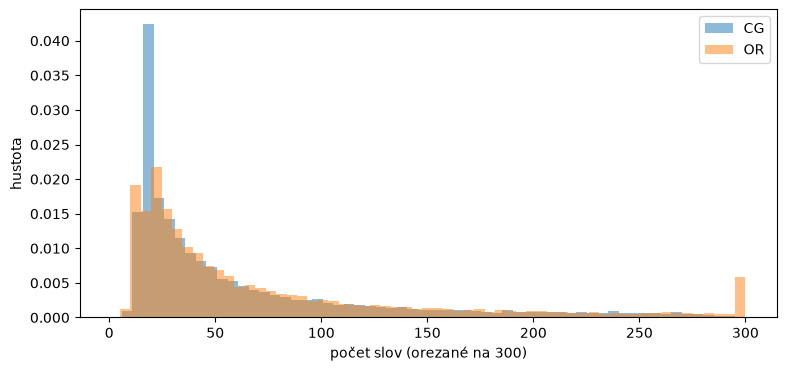

ROC-AUC len z počtu slov (kratší = CG): 0.546
  Books_5                        0.551
  Clothing_Shoes_and_Jewelry_5   0.544
  Electronics_5                  0.553
  Home_and_Kitchen_5             0.539
  Kindle_Store_5                 0.557
  Movies_and_TV_5                0.550
  Pet_Supplies_5                 0.542
  Sports_and_Outdoors_5          0.543
  Tools_and_Home_Improvement_5   0.543
  Toys_and_Games_5               0.538


In [6]:
from sklearn.metrics import roc_auc_score

t = df[txt].astype(str)
df["n_words"] = t.str.split().str.len()
df["n_chars"] = t.str.len()
display(df.groupby(lab)[["n_words", "n_chars"]].describe().T.round(1))

fig, ax = plt.subplots(figsize=(9, 4))
for l, g in df.groupby(lab):
    ax.hist(g["n_words"].clip(upper=300), bins=60, alpha=0.5, density=True, label=l)
ax.set_xlabel("počet slov (orezané na 300)")
ax.set_ylabel("hustota")
ax.legend()
plt.show()

print(f"ROC-AUC len z počtu slov (kratší = CG): {roc_auc_score(df['y'], -df['n_words']):.3f}")
for c, g in df.groupby(cat):
    print(f"  {c:30s} {roc_auc_score(g['y'], -g['n_words']):.3f}")

## 5. Duplicity a prekryv textov
- presné duplicity v rámci triedy a medzi triedami
- prekryv začiatkov textov (prvých 5 slov) medzi CG a OR – naznačuje, či generátor dostal začiatok pravej recenzie ako prompt

In [7]:
print("duplicitné texty celkovo:", t.duplicated().sum())
for l, g in df.groupby(lab):
    print(f"  {l}: {g[txt].duplicated().sum()}")
print("texty v oboch triedach:", len(set(t[df[lab] == 'CG']) & set(t[df[lab] == 'OR'])))

def prefix(s, k=5):
    return s.str.lower().str.split().str[:k].str.join(" ")

p_or = set(prefix(t[df[lab] == "OR"]))
p_cg = prefix(t[df[lab] == "CG"])
print(f"CG recenzie, ktorých prvých 5 slov sa vyskytuje aj v OR: {p_cg.isin(p_or).mean():.3f}")
print("najčastejšie spoločné začiatky:")
print(p_cg[p_cg.isin(p_or)].value_counts().head(10).to_dict())

duplicitné texty celkovo: 20
  CG: 19
  OR: 1
texty v oboch triedach: 0


CG recenzie, ktorých prvých 5 slov sa vyskytuje aj v OR: 0.059
najčastejšie spoločné začiatky:
{'i bought this for my': 38, 'i bought these for my': 21, 'this is one of the': 18, 'i got this for my': 15, 'this is a great little': 14, 'i bought this for a': 14, 'i purchased this for my': 14, 'i really enjoyed this book.': 14, 'i bought this as a': 11, 'this is one of my': 11}


## 6. Chýbajúce hodnoty

In [8]:
print(df[[cat, rat, lab, txt]].isna().sum().to_dict())
print("prázdne / len biele znaky:", (t.str.strip() == "").sum())

{'category': 0, 'rating': 0, 'label': 0, 'text_': 0}
prázdne / len biele znaky: 0


## 7. Formálne artefakty textu
Vlastnosti textu, ktoré nesúvisia s obsahom, ale môžu odlíšiť triedy:
- koniec textu: končí interpunkciou (`.`, `!`, `?`, úvodzovka, zátvorka) – generovaný text je často orezaný v polovici vety (limit dĺžky generovania)
- spojené vety bez medzery (`purchase.This`) – generované vety boli spájané bez medzery
- dvojitá medzera, nový riadok, číslice, `...`, text bez veľkých písmen, text začína malým písmenom

In [9]:
CHECKS = {
    "končí interpunkciou":       r"[.!?\"')\]]\s*$",
    "spojenie viet bez medzery": r"[a-z0-9)][.!?][A-Z]",
    "dvojitá medzera":           r"  ",
    "nový riadok":               r"\n",
    "číslica":                   r"\d",
    "úvodzovky \"":             r"\"",
    "... (tri bodky)":           r"\.\.\.",
    "začína malým písmenom":     r"^\s*[a-z]",
    "bez veľkých písmen":        r"^[^A-Z]*$",
    "ne-ASCII znak":             r"[^\x00-\x7f]",
    "HTML (<br)":                r"(?i)<br",
}

def artifact_stats(s):
    return {k: s.str.contains(p, regex=True).mean() for k, p in CHECKS.items()}

rows = {l: artifact_stats(t[df[lab] == l]) for l in ["OR", "CG"]}
art = pd.DataFrame(rows)
art["rozdiel CG - OR"] = art["CG"] - art["OR"]
print("Podiel recenzií s danou vlastnosťou:")
display(art.round(3))

Podiel recenzií s danou vlastnosťou:


,OR,CG,rozdiel CG - OR
končí interpunkciou,0.906,0.352,-0.554
spojenie viet bez medzery,0.000,0.285,0.284
dvojitá medzera,0.371,0.453,0.082
nový riadok,0.207,0.169,-0.037
číslica,0.325,0.219,-0.106
"úvodzovky """,0.113,0.064,-0.049
... (tri bodky),0.084,0.007,-0.078
začína malým písmenom,0.048,0.050,0.002
bez veľkých písmen,0.024,0.005,-0.019
ne-ASCII znak,0.000,0.000,0.000


In [10]:
# Posledný znak textu podľa triedy
for l in ["OR", "CG"]:
    print(l, t[df[lab] == l].str.rstrip().str[-1].value_counts(normalize=True).head(8).round(3).to_dict())

OR {'.': 0.779, '!': 0.112, 'e': 0.015, 's': 0.013, 't': 0.011, ')': 0.008, 'n': 0.006, '?': 0.006}
CG {'.': 0.346, 'e': 0.124, 't': 0.091, 'd': 0.068, 's': 0.067, 'y': 0.036, 'r': 0.034, 'a': 0.033}


In [11]:
# Ukážky: CG s orezaným koncom a so spojenými vetami
pd.set_option("display.max_colwidth", 300)
cg = t[df[lab] == "CG"]
print("CG, orezaný koniec:")
for s in cg[~cg.str.contains(CHECKS["končí interpunkciou"])].sample(4, random_state=0):
    print("  ...", repr(s[-120:]))
print("\nCG, spojenie viet bez medzery:")
for s in cg[cg.str.contains(CHECKS["spojenie viet bez medzery"])].sample(4, random_state=0):
    m = re.search(CHECKS["spojenie viet bez medzery"], s)
    print("  ...", repr(s[max(0, m.start() - 60): m.end() + 40]), "...")

CG, orezaný koniec:
  ... 'Having a household of 9, I have an 80 pound pit mix. He is a strong chewer and so we had to get a treat to'
  ... 'The slicer works easily and looks good.  It is very sharp and easy to use.  The bottom is not very flexible'
  ... "hecking her to see if she's happy or upset, and she's very happy and happy! The dog is a lab mix and it's nice to have a"
  ... 'Eye opening read with very little action and the writing is slow.  There is a lot of time'

CG, spojenie viet bez medzery:
  ... 'ok and the writing. I will definitely be reading the next one.I read this book in the last few days and' ...
  ... 'o our dog and he loves them. I will keep them for a long time.I bought this for a' ...
  ... '  The plastic parts are very sturdy.\n\nThis is a great product.I had this for a few months, and it was p' ...
  ... 'e is so funny and well acted. It is a must for any horror fan.I enjoyed the series. I love the show and' ...


## 8. Signál z artefaktov bez obsahu
- ROC-AUC jednotlivých artefaktov (binárny príznak)
- odhad, akú časť úlohy dokáže vyriešiť klasifikátor, ktorý nevidí obsah (detailne v notebooku 02)

In [12]:
for k, p in CHECKS.items():
    f = t.str.contains(p, regex=True).astype(int)
    auc = roc_auc_score(df["y"], f)
    print(f"{k:28s} ROC-AUC {max(auc, 1 - auc):.3f}  ({'CG' if auc >= 0.5 else 'OR'} častejšie)")

končí interpunkciou          ROC-AUC 0.777  (OR častejšie)


spojenie viet bez medzery    ROC-AUC 0.642  (CG častejšie)


dvojitá medzera              ROC-AUC 0.541  (CG častejšie)
nový riadok                  ROC-AUC 0.519  (OR častejšie)
číslica                      ROC-AUC 0.553  (OR častejšie)
úvodzovky "                  ROC-AUC 0.524  (OR častejšie)
... (tri bodky)              ROC-AUC 0.539  (OR častejšie)
začína malým písmenom        ROC-AUC 0.501  (CG častejšie)


bez veľkých písmen           ROC-AUC 0.510  (OR častejšie)


ne-ASCII znak                ROC-AUC 0.500  (CG častejšie)
HTML (<br)                   ROC-AUC 0.500  (CG častejšie)


## 9. Kategórie
- priemerná dĺžka a hlavné artefakty podľa kategórie
- podklad pre leave-one-category-out (FRD nemá viac generátorov, generalizácia sa testuje na neznámej kategórii)

In [13]:
def cat_row(g):
    s = g[txt].astype(str)
    return pd.Series({
        "n": len(g),
        "slov OR": g.loc[g["y"] == 0, "n_words"].mean(),
        "slov CG": g.loc[g["y"] == 1, "n_words"].mean(),
        "koniec interp. OR": s[g["y"] == 0].str.contains(CHECKS["končí interpunkciou"]).mean(),
        "koniec interp. CG": s[g["y"] == 1].str.contains(CHECKS["končí interpunkciou"]).mean(),
        "spojené vety CG": s[g["y"] == 1].str.contains(CHECKS["spojenie viet bez medzery"]).mean(),
    })

display(df.groupby(cat).apply(cat_row, include_groups=False).round(3))

,n,slov OR,slov CG,koniec interp. OR,koniec interp. CG,spojené vety CG
category,,,,,,
Books_5,4370.0,87.913,73.535,0.933,0.341,0.275
Clothing_Shoes_and_Jewelry_5,3848.0,61.473,50.693,0.878,0.395,0.278
Electronics_5,3988.0,75.619,61.828,0.909,0.326,0.246
Home_and_Kitchen_5,4056.0,65.811,55.330,0.920,0.347,0.294
Kindle_Store_5,4730.0,87.339,72.796,0.907,0.364,0.373
Movies_and_TV_5,3588.0,80.901,65.953,0.911,0.401,0.247
Pet_Supplies_5,4254.0,67.800,57.294,0.914,0.320,0.315
Sports_and_Outdoors_5,3946.0,68.489,57.476,0.898,0.347,0.232
Tools_and_Home_Improvement_5,3858.0,70.561,58.882,0.897,0.343,0.233


## Výsledok
- 40 432 recenzií, presne 20 216 OR a 20 216 CG; vyvážené aj v rámci každej z 10 kategórií
- hodnotenie: rovnaké rozdelenie v oboch triedach (5★ 60,9 % CG vs. 60,5 % OR) -> `category` ani `rating` nie sú zdrojom úniku labelu (na rozdiel od metadát vo FraudSquad)
- súbor je zoradený podľa kategórie a labelu -> pri rozdelení treba miešať
- dĺžka: CG kratšie (medián 35 vs. 42 slov, 174 vs. 224 znakov), rozdelenia sa prekrývajú; ROC-AUC len z počtu slov 0,546
- duplicity: 20 presných (19 CG, 1 OR), žiadny text v oboch triedach; 5,9 % CG začína rovnakými 5 slovami ako niektorá OR (bežné frázy typu „i bought this for my“)
- artefakty generovania (najsilnejší signál bez obsahu):
  - koniec interpunkciou: OR 90,6 %, CG 35,2 % (ROC-AUC 0,777) -> CG je často orezané v polovici vety
  - spojenie viet bez medzery: OR 0,0 %, CG 28,5 % (ROC-AUC 0,642) -> CG vzniklo spojením viacerých generovaných úsekov (`...next one.I read this book...`)
  - menšie rozdiely: dvojité medzery (CG 45 % vs. 37 %), `...` (OR 8,4 % vs. 0,7 %), číslice (OR 32,5 % vs. 21,9 %)
- žiadne HTML ani ne-ASCII znaky v žiadnej triede
- artefakty sú konzistentné vo všetkých kategóriách -> treba ich kontrolovať (notebook 02b), inak model môže detegovať spôsob generovania datasetu namiesto generovaného štýlu